# Task1

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd

df = pd.read_csv("user_study.csv")

print(df.columns.tolist())

['Timestamp', 'Q1. Leather back turtle [Method 1]', 'Q1. Leather back turtle [Method 2]', 'Q2. Cowboy boot [Method 1]', 'Q2. Cowboy boot [Method 2]', 'Q3. Motor Scooter [Method 1]', 'Q3. Motor Scooter [Method 2]', 'Q4. Daisy [Method 1]', 'Q4. Daisy [Method 2]', 'Q5. Padlock [Method 1]', 'Q5. Padlock [Method 2]', 'Q6. Bird house [Method 1]', 'Q6. Bird house [Method 2]', 'Q7. Golden Retriever [Method 1]', 'Q7. Golden Retriever [Method 2]', 'Q8. Sports Car [Method 1]', 'Q8. Sports Car [Method 2]', 'Q9. Broccoli [Method 1]', 'Q9. Broccoli [Method 2]', 'Q10. Violin [Method 1]', 'Q10. Violin [Method 2]', 'Q11. Great grey owl [Method 1]', 'Q11. Great grey owl [Method 2]', 'Q12. French bulldog [Method 1]', 'Q12. French bulldog [Method 2]', 'Q13. Gorilla [Method 1]', 'Q13. Gorilla [Method 2]', 'Q14. Drum [Method 1]', 'Q14. Drum [Method 2]', 'Q15. Wine bottle [Method 1]', 'Q15. Wine bottle [Method 2]', 'Q16. Orca [Method 1]', 'Q16. Orca [Method 2]', 'Q17. Grass hopper [Method 1]', 'Q17. Grass ho

In [ ]:
vital_method1_questions = [1, 3, 4, 5, 9, 11, 14, 16, 18, 19 ]
vital_method2_questions = [0, 2, 6, 7, 8, 10, 12, 13, 15, 17 ]

In [ ]:
assert set(vital_method1_questions).isdisjoint(set(vital_method2_questions))
assert sorted(vital_method1_questions + vital_method2_questions) == list(range(20))

In [ ]:
task1_cols = df.columns[1:41]

vital_ratings = []
structfv_ratings = []

for q in range(20):
    m1_col = task1_cols[2*q]
    m2_col = task1_cols[2*q + 1]

    if q in vital_method1_questions:
        # Method 1 = Vital, Method 2 = StructFV
        vital_ratings.extend(df[m1_col].dropna().astype(int).tolist())
        structfv_ratings.extend(df[m2_col].dropna().astype(int).tolist())
    else:
        # Method 1 = StructFV, Method 2 = Vital
        vital_ratings.extend(df[m2_col].dropna().astype(int).tolist())
        structfv_ratings.extend(df[m1_col].dropna().astype(int).tolist())

In [ ]:
ratings = [1, 2, 3, 4, 5]
vital_counts = [vital_ratings.count(r) for r in ratings]
struct_counts = [structfv_ratings.count(r) for r in ratings]

print("Vital counts:", vital_counts)
print("StructFV counts:", struct_counts)

Vital counts: [228, 224, 91, 33, 4]
StructFV counts: [51, 119, 195, 171, 44]


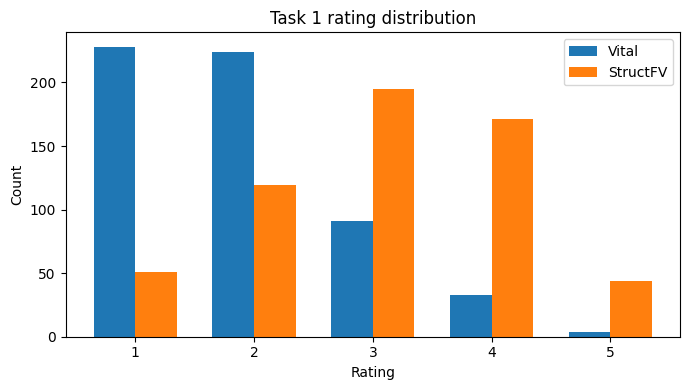

In [ ]:
x = np.arange(len(ratings))
width = 0.35

plt.figure(figsize=(7, 4))
plt.bar(x - width/2, vital_counts, width, label="Vital")
plt.bar(x + width/2, struct_counts, width, label="StructFV")

plt.xticks(x, ratings)
plt.xlabel("Rating")
plt.ylabel("Count")
plt.title("Task 1 rating distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
vital_total = len(vital_ratings)
struct_total = len(structfv_ratings)

vital_counts = [100 * vital_ratings.count(r) / vital_total for r in ratings]
struct_counts = [100 * structfv_ratings.count(r) / struct_total for r in ratings]

Method vs frequency

In [ ]:
ratings = [1, 2, 3, 4, 5]

vital_counts = [vital_ratings.count(r) for r in ratings]
struct_counts = [structfv_ratings.count(r) for r in ratings]

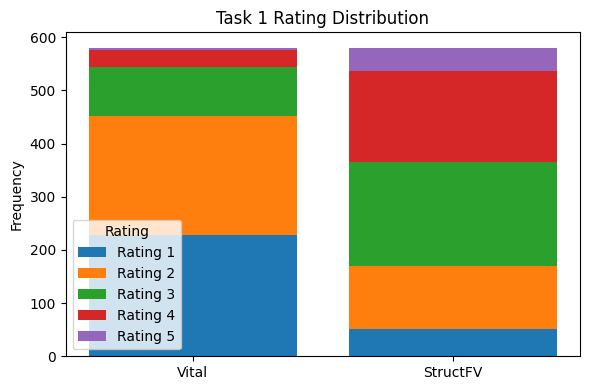

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

methods = ["Vital", "StructFV"]

counts = np.array([
    vital_counts,
    struct_counts
])

bottom = np.zeros(len(methods))

plt.figure(figsize=(6,4))

for i, rating in enumerate(ratings):
    plt.bar(
        methods,
        counts[:, i],
        bottom=bottom,
        label=f"Rating {rating}"
    )
    bottom += counts[:, i]

plt.ylabel("Frequency")
plt.title("Task 1 Rating Distribution")
plt.legend(title="Rating")
plt.tight_layout()
plt.show()

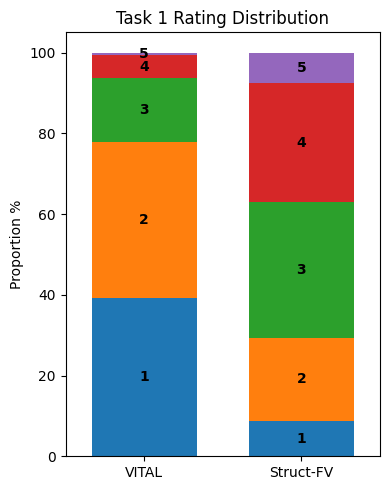

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

methods = ["VITAL", "Struct-FV"]
counts = counts / counts.sum(axis=1, keepdims=True) * 100

# Move bars closer together
x = np.array([0.0, 0.3])   # try 0.3, 0.4, 0.5

bottom = np.zeros(2)

plt.figure(figsize=(4,5))

for i, rating in enumerate(ratings):

    bars = plt.bar(
        x,
        counts[:, i],
        bottom=bottom,
        width=0.2
    )

    for j, bar in enumerate(bars):
        height = counts[j, i]

        if height > 0:
            plt.text(
                bar.get_x() + bar.get_width()/2,
                bottom[j] + height/2,
                str(rating),
                ha='center',
                va='center',
                fontsize=10,
                fontweight='bold'
            )

    bottom += counts[:, i]

plt.xticks(x, methods)

# tighten plot around bars
plt.xlim(-0.15, 0.45)

plt.ylabel("Proportion %")
plt.title("Task 1 Rating Distribution")
plt.tight_layout()
plt.show()

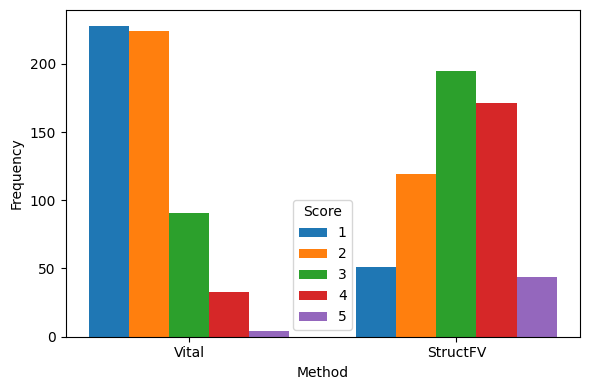

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

methods = ["Vital", "StructFV"]
ratings = [1, 2, 3, 4, 5]

counts = np.array([
    vital_counts,
    struct_counts
])

x = np.arange(len(methods))
width = 0.15

plt.figure(figsize=(6,4))

for i, rating in enumerate(ratings):
    plt.bar(
        x + (i-2)*width,
        counts[:, i],
        width,
        label=str(rating)
    )

plt.xticks(x, methods)
plt.xlabel("Method")
plt.ylabel("Frequency")
plt.legend(title="Score")
plt.tight_layout()
plt.show()

In [ ]:
deltas = []

for q in range(20):

    m1_col = task1_cols[2*q]
    m2_col = task1_cols[2*q + 1]

    if q in vital_method1_questions:
        vital = df[m1_col]
        struct = df[m2_col]
    else:
        vital = df[m2_col]
        struct = df[m1_col]

    deltas.extend((struct - vital).dropna().tolist())

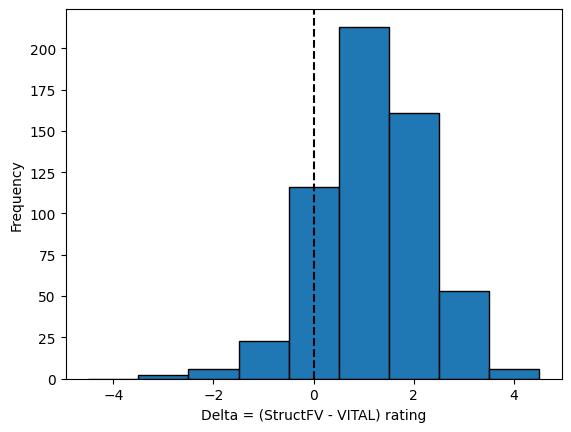

In [ ]:
plt.hist(
    deltas,
    bins=np.arange(-4.5, 5.5, 1),
    edgecolor="black"
)

plt.axvline(0, linestyle="--", color="black")
plt.xlabel("Delta = (StructFV - VITAL) rating")
plt.ylabel("Frequency")
plt.show()

In [ ]:
user_mean_deltas = []

for participant in range(len(df)):
    participant_deltas = []

    for q in range(20):
        m1_col = task1_cols[2*q]
        m2_col = task1_cols[2*q + 1]

        if q in vital_method1_questions:
            vital = df.loc[participant, m1_col]
            struct = df.loc[participant, m2_col]
        else:
            vital = df.loc[participant, m2_col]
            struct = df.loc[participant, m1_col]

        participant_deltas.append(struct - vital)

    user_mean_deltas.append(np.mean(participant_deltas))

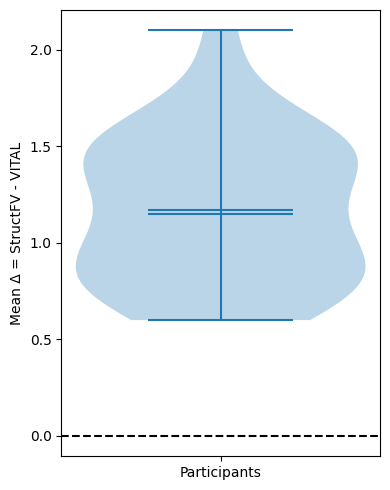

In [ ]:
plt.figure(figsize=(4, 5))

plt.violinplot(
    user_mean_deltas,
    showmeans=True,
    showmedians=True
)

plt.axhline(0, linestyle="--", color="black")

plt.ylabel("Mean Δ = StructFV - VITAL")
plt.xticks([1], ["Participants"])

plt.tight_layout()
plt.show()

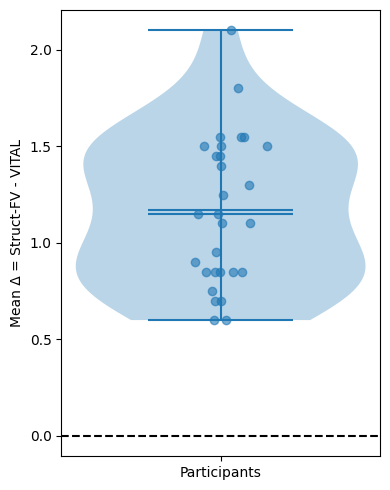

In [ ]:
plt.figure(figsize=(4,5))

plt.violinplot(
    user_mean_deltas,
    showmeans=True,
    showmedians=True
)

x = np.random.normal(1, 0.03, len(user_mean_deltas))
plt.scatter(x, user_mean_deltas, alpha=0.6)

plt.axhline(0, linestyle="--", color="black")

plt.ylabel("Mean Δ = Struct-FV - VITAL")
plt.xticks([1], ["Participants"])

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

median_delta = np.median(user_mean_deltas)
mean_delta = np.mean(user_mean_deltas)

print("Median:", median_delta)
print("Mean:", mean_delta)

Median: 1.15
Mean: 1.1672413793103449


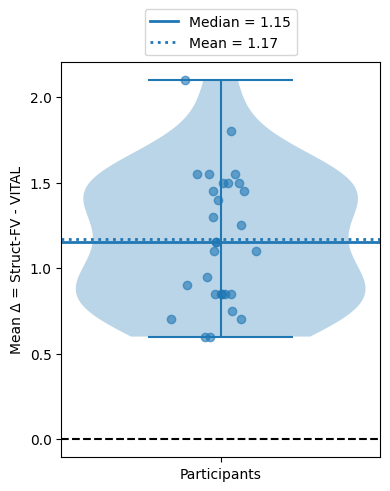

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

median_delta = np.median(user_mean_deltas)
mean_delta = np.mean(user_mean_deltas)

plt.figure(figsize=(4,5))

plt.violinplot(
    user_mean_deltas,
    showmeans=False,
    showmedians=False
)

# participant points
x = np.random.normal(1, 0.03, len(user_mean_deltas))
plt.scatter(x, user_mean_deltas, alpha=0.6)

# zero baseline
plt.axhline(0, linestyle='--', color='black')

# median
plt.axhline(
    median_delta,
    linewidth=2,
    label=f"Median = {median_delta:.2f}"
)

# mean
plt.axhline(
    mean_delta,
    linestyle=':',
    linewidth=2,
    label=f"Mean = {mean_delta:.2f}"
)

plt.ylabel("Mean Δ = Struct-FV - VITAL")
plt.xticks([1], ["Participants"])
plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15)
)
plt.tight_layout()
plt.show()

# Task 2

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("user_study.csv")

def analyze_task(df, task_cols, n_questions, method1_vital_questions, title):
    """
    task_cols: the contiguous columns for this task, in order:
               q0 m1, q0 m2, q1 m1, q1 m2, ...
    n_questions: number of questions in the task
    method1_vital_questions: list of question indices where Method 1 = Vital
    title: plot title
    """
    vital_ratings = []
    structfv_ratings = []
    user_mean_deltas = []

    for row_idx in range(len(df)):
        participant_deltas = []

        for q in range(n_questions):
            m1_col = task_cols[2*q]
            m2_col = task_cols[2*q + 1]

            m1 = df.loc[row_idx, m1_col]
            m2 = df.loc[row_idx, m2_col]

            if pd.isna(m1) or pd.isna(m2):
                continue

            m1 = float(m1)
            m2 = float(m2)

            if q in method1_vital_questions:
                vital = m1
                struct = m2
            else:
                vital = m2
                struct = m1

            vital_ratings.append(vital)
            structfv_ratings.append(struct)
            participant_deltas.append(struct - vital)

        if participant_deltas:
            user_mean_deltas.append(np.mean(participant_deltas))

    return vital_ratings, structfv_ratings, user_mean_deltas

In [ ]:
task2_cols = df.columns[41:59]   # adjust if your file has extra columns

In [ ]:
task2_method1_questions = [1, 3, 5 ]  # questions where Method 1 = Vital
# Method 1 = StructFV = [0, 2, 4, 6, 7, 8]

In [ ]:
task2_vital, task2_struct, task2_user_mean_deltas = analyze_task(
    df=df,
    task_cols=task2_cols,
    n_questions=9,
    method1_vital_questions=task2_method1_questions,
    title="Task 2"
)

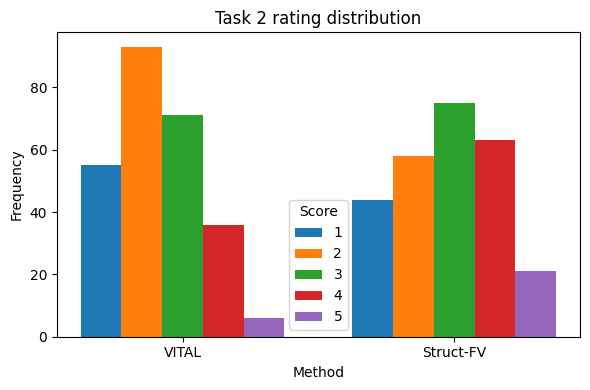

In [ ]:
ratings = [1, 2, 3, 4, 5]
vital_counts = [task2_vital.count(r) for r in ratings]
struct_counts = [task2_struct.count(r) for r in ratings]

methods = ["VITAL", "Struct-FV"]
counts = np.array([vital_counts, struct_counts])

x = np.arange(len(methods))
width = 0.15

plt.figure(figsize=(6, 4))

for i, rating in enumerate(ratings):
    plt.bar(x + (i - 2) * width, counts[:, i], width, label=str(rating))

plt.xticks(x, methods)
plt.xlabel("Method")
plt.ylabel("Frequency")
plt.title("Task 2 rating distribution")
plt.legend(title="Score")
plt.tight_layout()
plt.show()

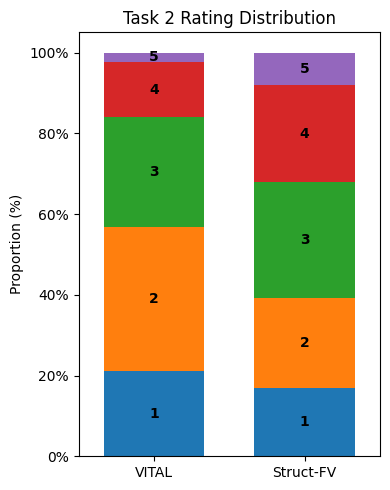

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ratings = [1, 2, 3, 4, 5]

vital_counts = [task2_vital.count(r) for r in ratings]
struct_counts = [task2_struct.count(r) for r in ratings]

counts = np.array([
    vital_counts,
    struct_counts
])

# Convert to percentages
counts = counts / counts.sum(axis=1, keepdims=True) * 100

methods = ["VITAL", "Struct-FV"]

# Bring bars closer together
x = np.array([0.0, 0.3])

bottom = np.zeros(2)

plt.figure(figsize=(4,5))

for i, rating in enumerate(ratings):

    bars = plt.bar(
        x,
        counts[:, i],
        bottom=bottom,
        width=0.2
    )

    # Put rating labels inside segments
    for j, bar in enumerate(bars):
        height = counts[j, i]

        if height > 2:   # skip tiny segments
            plt.text(
                bar.get_x() + bar.get_width()/2,
                bottom[j] + height/2,
                str(rating),
                ha='center',
                va='center',
                fontsize=10,
                fontweight='bold'
            )

    bottom += counts[:, i]

plt.xticks(x, methods)
plt.xlim(-0.15, 0.45)

plt.ylabel("Proportion (%)")
plt.title("Task 2 Rating Distribution")

ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter())

plt.tight_layout()
plt.show()

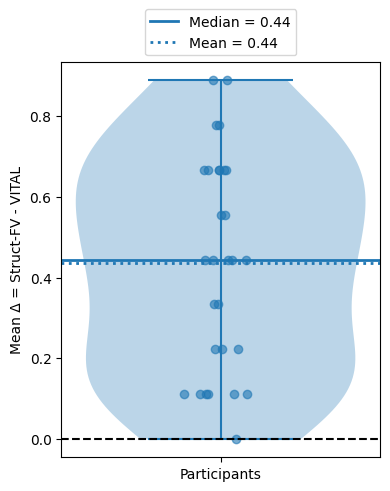

In [ ]:
median_delta = np.median(task2_user_mean_deltas)
mean_delta = np.mean(task2_user_mean_deltas)

plt.figure(figsize=(4, 5))

plt.violinplot(task2_user_mean_deltas, showmeans=False, showmedians=False)

x = np.random.normal(1, 0.03, len(task2_user_mean_deltas))
plt.scatter(x, task2_user_mean_deltas, alpha=0.6)

plt.axhline(0, linestyle="--", color="black")
plt.axhline(median_delta, linewidth=2, label=f"Median = {median_delta:.2f}")
plt.axhline(mean_delta, linestyle=":", linewidth=2, label=f"Mean = {mean_delta:.2f}")

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15)
)
plt.ylabel("Mean Δ = Struct-FV - VITAL")
plt.xticks([1], ["Participants"])
# plt.title("Task 2")
plt.tight_layout()
plt.show()

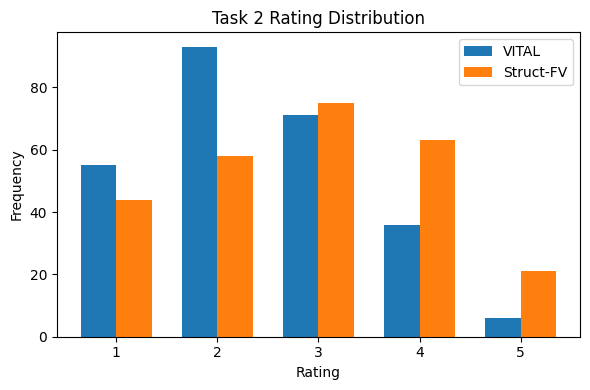

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(ratings))
width = 0.35

plt.figure(figsize=(6,4))

plt.bar(
    x - width/2,
    vital_counts,
    width,
    label="VITAL"
)

plt.bar(
    x + width/2,
    struct_counts,
    width,
    label="Struct-FV"
)

plt.xticks(x, ratings)
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.title("Task 2 Rating Distribution")

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
vital_counts = np.array(vital_counts)
struct_counts = np.array(struct_counts)

vital_pct = 100 * vital_counts / vital_counts.sum()
struct_pct = 100 * struct_counts / struct_counts.sum()

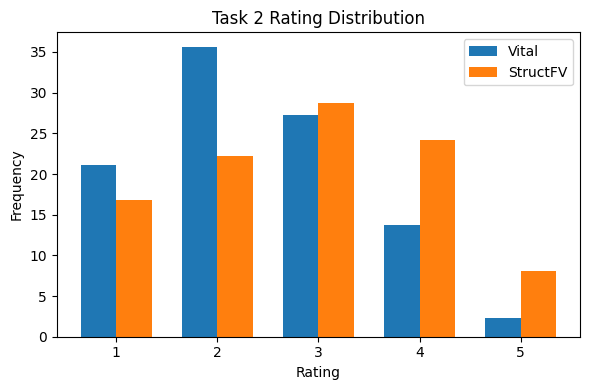

In [ ]:

x = np.arange(len(ratings))
width = 0.35

plt.figure(figsize=(6,4))

plt.bar(
    x - width/2,
    vital_pct,
    width,
    label="Vital"
)

plt.bar(
    x + width/2,
    struct_pct,
    width,
    label="StructFV"
)

plt.xticks(x, ratings)
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.title("Task 2 Rating Distribution")

plt.legend()
plt.tight_layout()
plt.show()

# Task3

In [ ]:
df.columns[59]

'Subsets'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_hub as hub
from scipy.spatial.distance import cosine

df = pd.read_csv("user_study.csv")

# Column that stores whether the participant used # or $
side_col = df.columns[59] # change this

task3_cols = df.columns[60:76]   # adjust start/end to your CSV

first8_cols = list(task3_cols[:8])
second8_cols = list(task3_cols[8:16])


In [ ]:
ground_truth = [
    "Lion",
    "Pizza",
    "Ambulance",
    "Lemon",
    "Soccer ball",
    "Elephant",
    "Tiger",
    "Rocking Chair",
]

In [ ]:
# Example only — fill with your real mapping
hash_map = [
    {"gt_idx": 0, "method": "StructFV"},
    {"gt_idx": 1, "method": "StructFV"},
    {"gt_idx": 2, "method": "StructFV"},
    {"gt_idx": 3, "method": "StructFV"},
    {"gt_idx": 4, "method": "VITAL"},
    {"gt_idx": 5, "method": "VITAL"},
    {"gt_idx": 6, "method": "VITAL"},
    {"gt_idx": 7, "method": "VITAL"},
]

dollar_map = [
    {"gt_idx": 0, "method": "VITAL"},
    {"gt_idx": 1, "method": "VITAL"},
    {"gt_idx": 6, "method": "StructFV"},
    {"gt_idx": 7, "method": "StructFV"},
    {"gt_idx": 3, "method": "VITAL"},
    {"gt_idx": 2, "method": "VITAL"},
    {"gt_idx": 4, "method": "StructFV"},
    {"gt_idx": 5, "method": "StructFV"},
]

In [ ]:
use = hub.load("https://tfhub.dev/google/universal-sentence-encoder/4")

def similarity(a, b):
    emb = use([str(a), str(b)]).numpy()
    return 1 - cosine(emb[0], emb[1])

def is_filled(x):
    return pd.notna(x) and str(x).strip() != ""

In [ ]:
print("Task 3 columns:", len(task3_cols))
print(task3_cols)
print("first8:", len(first8_cols), first8_cols)
print("second8:", len(second8_cols), second8_cols)

Task 3 columns: 16
Index(['Q1.', 'Q2.', 'Q3. ', 'Q4. ', 'Q5. ', 'Q6. ', 'Q7. ', 'Q8. ', 'Q1..1',
       'Q2..1', 'Q3.', 'Q4.', 'Q5.', 'Q6.', 'Q7.', 'Q8.'],
      dtype='object')
first8: 8 ['Q1.', 'Q2.', 'Q3. ', 'Q4. ', 'Q5. ', 'Q6. ', 'Q7. ', 'Q8. ']
second8: 8 ['Q1..1', 'Q2..1', 'Q3.', 'Q4.', 'Q5.', 'Q6.', 'Q7.', 'Q8.']


VITAL
  n = 116
  median = 1.0
  q05 = 0.24860233068466187
  q95 = 1.0
StructFV
  n = 116
  median = 1.0
  q05 = 0.3006019592285156
  q95 = 1.0


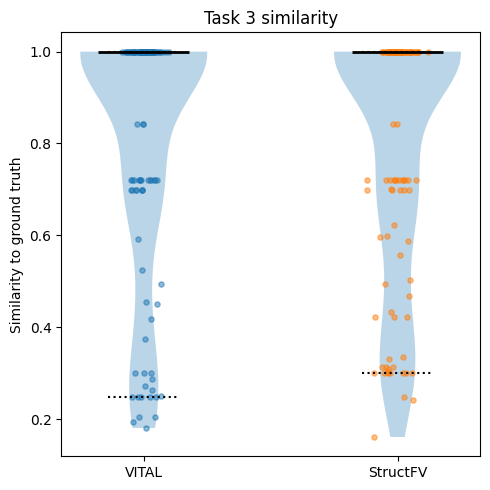

In [ ]:
scores = {"VITAL": [], "StructFV": []}

for _, row in df.iterrows():
    side = str(row[side_col]).strip()

    if side == "#":
        cols = first8_cols
        mapping = hash_map
    else:
        cols = second8_cols
        mapping = dollar_map

    for pos in range(8):
        ans = row[cols[pos]]
        if pd.isna(ans) or str(ans).strip() == "":
            continue

        gt_idx = mapping[pos]["gt_idx"]
        method = mapping[pos]["method"]
        gt = ground_truth[gt_idx]

        scores[method].append(similarity(ans, gt))

# Summary stats
for method in ["VITAL", "StructFV"]:
    arr = np.array(scores[method], dtype=float)
    print(method)
    print("  n =", len(arr))
    print("  median =", np.median(arr))
    print("  q05 =", np.quantile(arr, 0.05))
    print("  q95 =", np.quantile(arr, 0.95))

# Violin plot
data = [scores["VITAL"], scores["StructFV"]]

plt.figure(figsize=(5, 5))
plt.violinplot(
    data,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

for i, vals in enumerate(data, start=1):
    vals = np.array(vals, dtype=float)

    x = np.random.normal(i, 0.04, size=len(vals))
    plt.scatter(x, vals, s=14, alpha=0.5)

    med = np.median(vals)
    q05 = np.quantile(vals, 0.05)
    q95 = np.quantile(vals, 0.95)

    plt.hlines(med, i - 0.18, i + 0.18, colors="black", linewidth=2)
    plt.hlines([q05, q95], i - 0.14, i + 0.14, colors="black", linestyles="dotted", linewidth=1.5)

plt.xticks([1, 2], ["VITAL", "StructFV"])
plt.ylabel("Similarity to ground truth")
plt.title("Task 3 similarity")
plt.tight_layout()
plt.show()

In [ ]:
summary = []

for method in ["VITAL", "StructFV"]:
    arr = np.array(scores[method])

    summary.append({
        "Method": method,
        "n": len(arr),
        "Mean": np.mean(arr),
        "Median": np.median(arr),
        "q05": np.quantile(arr, 0.05),
        "q95": np.quantile(arr, 0.95),
        "Std": np.std(arr, ddof=1),
        "Min": np.min(arr),
        "Max": np.max(arr),
    })

summary_df = pd.DataFrame(summary)
display(summary_df.round(3))

,Method,n,Mean,Median,q05,q95,Std,Min,Max
0,VITAL,116,0.811,1.0,0.249,1.0,0.273,0.181,1.0
1,StructFV,116,0.798,1.0,0.301,1.0,0.269,0.161,1.0


In [ ]:
for method in ["VITAL", "StructFV"]:
    arr = np.array(scores[method])

    print(method)
    print("mean   =", np.mean(arr))
    print("median =", np.median(arr))
    print("std    =", np.std(arr))
    print("min    =", np.min(arr))
    print("max    =", np.max(arr))

VITAL
mean   = 0.81116027
median = 1.0
std    = 0.2720447
min    = 0.18074256
max    = 1.0
StructFV
mean   = 0.7984966
median = 1.0
std    = 0.2674379
min    = 0.16109902
max    = 1.0


In [ ]:
# How many are exactly 1 similarity
for method in ["VITAL", "StructFV"]:
    arr = np.array(scores[method])

    print(
        method,
        np.sum(np.isclose(arr, 1.0)),
        "/",
        len(arr)
    )

VITAL 70 / 116
StructFV 67 / 116


# Extra

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_hub as hub
from scipy.spatial.distance import cosine

# -----------------------
# Load CSV
# -----------------------
df = pd.read_csv("user_study.csv")

# -----------------------
# Column setup
# -----------------------
# 0-based index of the side column
side_col = df.columns[59]

# Task 3 answer columns
# Adjust these if your CSV layout is different
task3_cols = df.columns[60:76]   # 16 columns total
first8_cols = list(task3_cols[:8])
second8_cols = list(task3_cols[8:16])

print("side_col:", side_col)
print("Task 3 columns:", len(task3_cols))
print("first8_cols:", len(first8_cols), first8_cols)
print("second8_cols:", len(second8_cols), second8_cols)


ground_truth = [
    "Lion",
    "Pizza",
    "Ambulance",
    "Lemon",
    "Soccer ball",
    "Elephant",
    "Tiger",
    "Rocking Chair",
]


hash_map = [
    {"gt_idx": 0, "method": "StructFV"},
    {"gt_idx": 1, "method": "StructFV"},
    {"gt_idx": 2, "method": "StructFV"},
    {"gt_idx": 3, "method": "StructFV"},
    {"gt_idx": 4, "method": "Vital"},
    {"gt_idx": 5, "method": "Vital"},
    {"gt_idx": 6, "method": "Vital"},
    {"gt_idx": 7, "method": "Vital"},
]

dollar_map = [
    {"gt_idx": 0, "method": "Vital"},
    {"gt_idx": 1, "method": "Vital"},
    {"gt_idx": 6, "method": "StructFV"},
    {"gt_idx": 7, "method": "StructFV"},
    {"gt_idx": 3, "method": "Vital"},
    {"gt_idx": 2, "method": "Vital"},
    {"gt_idx": 4, "method": "StructFV"},
    {"gt_idx": 5, "method": "StructFV"},
]


use = hub.load("https://tfhub.dev/google/universal-sentence-encoder/4")

def similarity(a, b):
    emb = use([str(a), str(b)]).numpy()
    return 1 - cosine(emb[0], emb[1])

def is_filled(x):
    return pd.notna(x) and str(x).strip() != ""


scores = {"Vital": [], "StructFV": []}
results = {"Vital": [], "StructFV": []}

for _, row in df.iterrows():
    side = str(row[side_col]).strip()

    if side == "#":
        cols = first8_cols
        mapping = hash_map
    else:
        cols = second8_cols
        mapping = dollar_map

    n = min(len(cols), len(mapping))

    for pos in range(n):
        ans = row[cols[pos]]

        if not is_filled(ans):
            continue

        gt_idx = mapping[pos]["gt_idx"]
        method = mapping[pos]["method"]
        gt = ground_truth[gt_idx]

        sim = similarity(ans, gt)

        scores[method].append(sim)
        results[method].append({
            "similarity": sim,
            "answer": str(ans),
            "ground_truth": gt,
            "gt_idx": gt_idx,
            "column": cols[pos],
            "side": side,
        })

# -----------------------
# Summary table
# -----------------------
summary = []
for method in ["Vital", "StructFV"]:
    arr = np.array(scores[method], dtype=float)
    summary.append({
        "Method": method,
        "n": len(arr),
        "Mean": np.mean(arr),
        "Median": np.median(arr),
        "q05": np.quantile(arr, 0.05),
        "q95": np.quantile(arr, 0.95),
        "Std": np.std(arr, ddof=1),
        "Min": np.min(arr),
        "Max": np.max(arr),
        "Exact_1.0": int(np.sum(np.isclose(arr, 1.0))),
    })

summary_df = pd.DataFrame(summary)
display(summary_df.round(3))


side_col: Subsets
Task 3 columns: 16
first8_cols: 8 ['Q1.', 'Q2.', 'Q3. ', 'Q4. ', 'Q5. ', 'Q6. ', 'Q7. ', 'Q8. ']
second8_cols: 8 ['Q1..1', 'Q2..1', 'Q3.', 'Q4.', 'Q5.', 'Q6.', 'Q7.', 'Q8.']


,Method,n,Mean,Median,q05,q95,Std,Min,Max,Exact_1.0
0,Vital,116,0.811,1.0,0.249,1.0,0.273,0.181,1.0,70
1,StructFV,116,0.798,1.0,0.301,1.0,0.269,0.161,1.0,67


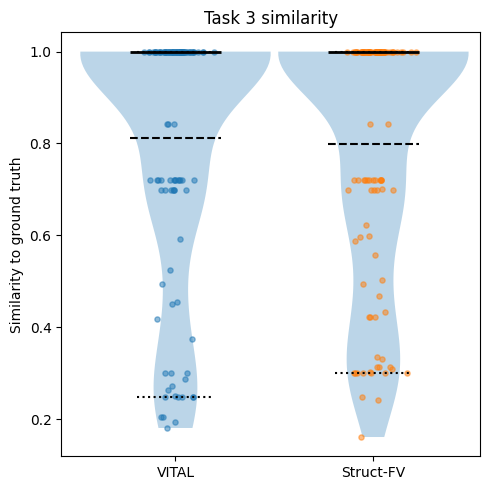


Vital
0.181 | GT='Ambulance' | Answer='vanfootball' | Column='Q6.' | Side='$'
0.194 | GT='Pizza' | Answer='-' | Column='Q2..1' | Side='$'
0.204 | GT='Soccer ball' | Answer='monkey' | Column='Q5. ' | Side='#'
0.204 | GT='Soccer ball' | Answer='monkey' | Column='Q5. ' | Side='#'
0.249 | GT='Ambulance' | Answer='Car' | Column='Q6.' | Side='$'
0.249 | GT='Ambulance' | Answer='car' | Column='Q6.' | Side='$'
0.249 | GT='Ambulance' | Answer='car' | Column='Q6.' | Side='$'
0.249 | GT='Ambulance' | Answer='Car' | Column='Q6.' | Side='$'
0.249 | GT='Ambulance' | Answer='Car' | Column='Q6.' | Side='$'
0.251 | GT='Tiger' | Answer='Annihilation' | Column='Q7. ' | Side='#'

StructFV
0.161 | GT='Soccer ball' | Answer='-' | Column='Q7.' | Side='$'
0.242 | GT='Ambulance' | Answer='bus' | Column='Q3. ' | Side='#'
0.249 | GT='Ambulance' | Answer='car' | Column='Q3. ' | Side='#'
0.301 | GT='Ambulance' | Answer='van' | Column='Q3. ' | Side='#'
0.301 | GT='Ambulance' | Answer='van' | Column='Q3. ' | Side='

In [ ]:


data = [scores["Vital"], scores["StructFV"]]

positions = [1.0, 1.52]

plt.figure(figsize=(5, 5))
plt.violinplot(
    data,
    positions=positions,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

for i, vals in enumerate(data):
    vals = np.array(vals, dtype=float)

    pos = positions[i]

    x = np.random.normal(pos, 0.03, size=len(vals))
    plt.scatter(x, vals, s=14, alpha=0.5)

    med = np.median(vals)
    q05 = np.quantile(vals, 0.05)
    q95 = np.quantile(vals, 0.95)
    mean = np.mean(vals)

    plt.hlines(med, pos - 0.12, pos + 0.12,
               colors="black", linewidth=2)

    plt.hlines([q05, q95], pos - 0.10, pos + 0.10,
               colors="black", linestyles="dotted", linewidth=1.5)

    plt.hlines(mean, pos - 0.12, pos + 0.12,
               colors="black", linestyles="dashed", linewidth=1.5)

plt.xticks(positions, ["VITAL", "Struct-FV"])
plt.xlim(0.7, 1.8)

plt.ylabel("Similarity to ground truth")
plt.title("Task 3 similarity")
plt.tight_layout()
plt.xlim(0.7, 1.8)
plt.show()


# -----------------------
# Worst matches
# -----------------------
for method in ["Vital", "StructFV"]:
    print(f"\n{'='*20}")
    print(method)
    print(f"{'='*20}")

    worst = sorted(results[method], key=lambda x: x["similarity"])[:10]

    for item in worst:
        print(
            f"{item['similarity']:.3f} | "
            f"GT='{item['ground_truth']}' | "
            f"Answer='{item['answer']}' | "
            f"Column='{item['column']}' | "
            f"Side='{item['side']}'"
        )